In [1]:
import os

NOTEBOOK_NAME = 'Training15ClassOutputs'
# Mendukung eksekusi di lingkungan WSL (/mnt/d/...) maupun Windows lokal (D:/...)
if os.path.exists('/mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks'):
    BASE_DIR = f'/mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/{NOTEBOOK_NAME}'
elif os.path.exists('D:/Projects/SIBI Recognition Lecturers/Backend/notebooks'):
    BASE_DIR = f'D:/Projects/SIBI Recognition Lecturers/Backend/notebooks/{NOTEBOOK_NAME}'
else:
    BASE_DIR = os.path.abspath(NOTEBOOK_NAME)

os.makedirs(BASE_DIR, exist_ok=True)
os.chdir(BASE_DIR)
print('Working directory sekarang:', os.getcwd())


Working directory sekarang: /mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/Training15ClassOutputs


In [2]:
%pip install -q numpy==1.26.4 tensorflow==2.17.0 matplotlib==3.9.4 scikit-learn==1.5.2 protobuf==4.25.3


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from keras.utils import to_categorical
from keras.models import Model
from keras.layers import (
    Input, Dense, Dropout, BatchNormalization,
    Bidirectional, LSTM, Layer, GaussianNoise
)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.regularizers import l2

# ====== KONFIGURASI EKSPERIMEN — UBAH DI SINI SAJA ======
import datetime

N_EPOCHS = 500
RUN_TIMESTAMP = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
PATH_CONFIGURATION_GENERAL = f'Epoch{N_EPOCHS}_{RUN_TIMESTAMP}'
os.makedirs(PATH_CONFIGURATION_GENERAL, exist_ok=True)
print(f'Output eksperimen ini akan disimpan ke folder: {PATH_CONFIGURATION_GENERAL}')
# ==========================================================

print(f'TensorFlow  : {tf.__version__}')
print(f'Keras       : {tf.keras.__version__}')
print(f'GPU tersedia: {tf.config.list_physical_devices("GPU")}')

2026-10-27 16:28:52.909154: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-27 16:28:52.939130: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-27 16:28:52.957763: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-27 16:28:52.962995: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-27 16:28:52.983489: I tensorflow/core/platform/cpu_feature_guar

Output eksperimen ini akan disimpan ke folder: Epoch500_20261027_162855
TensorFlow  : 2.17.0
Keras       : 3.12.4
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793093335.636604  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793093335.736074  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793093335.736121  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [4]:
# HANYA menggunakan KeypointsUpdate (hasil ekstraksi baru yang bersih)
if os.path.exists('/mnt/d/Projects/SIBI Recognition Lecturers/KeypointsUpdate'):
    DATA_PATH = '/mnt/d/Projects/SIBI Recognition Lecturers/KeypointsUpdate'
elif os.path.exists('D:/Projects/SIBI Recognition Lecturers/KeypointsUpdate'):
    DATA_PATH = 'D:/Projects/SIBI Recognition Lecturers/KeypointsUpdate'
else:
    DATA_PATH = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'KeypointsUpdate'))

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Folder KeypointsUpdate tidak ditemukan di: {DATA_PATH}. Jalankan extract_keypoints_from_video.py terlebih dahulu!")

print('Menggunakan DATA_PATH:', DATA_PATH)

sequence_length = 30
FITUR_PER_FRAME = 258
MODEL_OUTPUT    = f'{PATH_CONFIGURATION_GENERAL}/model15class.keras'
MODEL_OUTPUT_H5  = f'{PATH_CONFIGURATION_GENERAL}/model15class.h5'
TEMP_CHECKPOINT = f'{PATH_CONFIGURATION_GENERAL}/temp_checkpoint.keras'

actions = np.array([
    'Adik', 'Apa', 'Ayah', 'Baik', 'Berapa', 'Bertemu', 'Cantik', 'Dari',
    'Dia', 'Dimana', 'Ganteng', 'Gemuk', 'Hallo', 'Hobi', 'Ibu'
])
POSE_DIM   = 132
LH_DIM     = 63
RH_DIM     = 63
POSE_END   = POSE_DIM
LH_END     = POSE_END + LH_DIM
RH_END     = LH_END + RH_DIM

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Kelas yang dilatih :', actions)
print('Jumlah kelas        :', len(actions))
print('Sequence length     :', sequence_length)
print('Fitur per frame     :', FITUR_PER_FRAME)
print('  - Pose : 0..{}    (132 = 33 x 4)'.format(POSE_END - 1))
print('  - LH   : {}..{}  (63 = 21 x 3)'.format(POSE_END, LH_END - 1))
print('  - RH   : {}..{}  (63 = 21 x 3)'.format(LH_END, RH_END - 1))
print('Output model        :', MODEL_OUTPUT)

os.makedirs(os.path.dirname(MODEL_OUTPUT), exist_ok=True)
os.makedirs(os.path.dirname(TEMP_CHECKPOINT), exist_ok=True)
print('✅ Folder output siap:', os.path.dirname(MODEL_OUTPUT))


Menggunakan DATA_PATH: /mnt/d/Projects/SIBI Recognition Lecturers/KeypointsUpdate
Kelas yang dilatih : ['Adik' 'Apa' 'Ayah' 'Baik' 'Berapa' 'Bertemu' 'Cantik' 'Dari' 'Dia'
 'Dimana' 'Ganteng' 'Gemuk' 'Hallo' 'Hobi' 'Ibu']
Jumlah kelas        : 15
Sequence length     : 30
Fitur per frame     : 258
  - Pose : 0..131    (132 = 33 x 4)
  - LH   : 132..194  (63 = 21 x 3)
  - RH   : 195..257  (63 = 21 x 3)
Output model        : Epoch500_20261027_162855/model15class.keras
✅ Folder output siap: Epoch500_20261027_162855


In [5]:
label_map = {label: num for num, label in enumerate(actions)}
print('Label map:', label_map)

sequences, labels = [], []

for action in actions:
    action_path = os.path.join(DATA_PATH, action)

    if not os.path.exists(action_path):
        print(f'⚠️  Folder tidak ditemukan: {action_path}')
        continue

    sequence_folders = sorted(
        [f for f in os.listdir(action_path) if f.isdigit()],
        key=int
    )

    loaded, skipped = 0, 0
    for sequence in sequence_folders:
        window = []
        try:
            for frame_num in range(sequence_length):
                res = np.load(os.path.join(action_path, sequence, f'{frame_num}.npy'))
                if res.shape[0] != FITUR_PER_FRAME:
                    raise ValueError(f'Fitur {res.shape[0]} != {FITUR_PER_FRAME} — cek extract_keypoints!')
                window.append(res)
            sequences.append(np.array(window))
            labels.append(label_map[action])
            loaded += 1
        except Exception:
            skipped += 1

    print(f'  {action:12s}: {loaded} dimuat, {skipped} dilewati')

X     = np.array(sequences, dtype=np.float32)
y_int = np.array(labels)
y     = to_categorical(y_int, num_classes=len(actions))

print(f'\n✅ Shape X : {X.shape}')
print(f'✅ Shape y : {y.shape}')
print('\nDistribusi kelas:')
for u, c in zip(*np.unique(y_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c} sequence')

Label map: {'Adik': 0, 'Apa': 1, 'Ayah': 2, 'Baik': 3, 'Berapa': 4, 'Bertemu': 5, 'Cantik': 6, 'Dari': 7, 'Dia': 8, 'Dimana': 9, 'Ganteng': 10, 'Gemuk': 11, 'Hallo': 12, 'Hobi': 13, 'Ibu': 14}
  Adik        : 101 dimuat, 0 dilewati
  Apa         : 100 dimuat, 0 dilewati
  Ayah        : 97 dimuat, 0 dilewati
  Baik        : 99 dimuat, 0 dilewati
  Berapa      : 101 dimuat, 0 dilewati
  Bertemu     : 101 dimuat, 0 dilewati
  Cantik      : 99 dimuat, 0 dilewati
  Dari        : 101 dimuat, 0 dilewati
  Dia         : 100 dimuat, 0 dilewati
  Dimana      : 100 dimuat, 0 dilewati
  Ganteng     : 99 dimuat, 0 dilewati
  Gemuk       : 99 dimuat, 0 dilewati
  Hallo       : 101 dimuat, 0 dilewati
  Hobi        : 101 dimuat, 0 dilewati
  Ibu         : 102 dimuat, 0 dilewati

✅ Shape X : (1501, 30, 258)
✅ Shape y : (1501, 15)

Distribusi kelas:
  Adik        : 101 sequence
  Apa         : 100 sequence
  Ayah        : 97 sequence
  Baik        : 99 sequence
  Berapa      : 101 sequence
  Bertemu    

In [6]:
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X, y_int, test_size=0.30, random_state=SEED, stratify=y_int
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED, stratify=y_temp_raw
)

print(f'Train (asli) : {X_train_raw.shape[0]} sequence')
print(f'Val   (asli) : {X_val_raw.shape[0]} sequence')
print(f'Test  (asli) : {X_test_raw.shape[0]} sequence')
print('\nDistribusi train asli:')
for u, c in zip(*np.unique(y_train_raw, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')

Train (asli) : 1050 sequence
Val   (asli) : 225 sequence
Test  (asli) : 226 sequence

Distribusi train asli:
  Adik        : 71
  Apa         : 70
  Ayah        : 68
  Baik        : 69
  Berapa      : 71
  Bertemu     : 71
  Cantik      : 69
  Dari        : 71
  Dia         : 70
  Dimana      : 70
  Ganteng     : 69
  Gemuk       : 69
  Hallo       : 70
  Hobi        : 71
  Ibu         : 71


In [7]:
def split_features(seq):
    """Pisah seq (T, 258) → pose (T, 33, 4), lh (T, 21, 3), rh (T, 21, 3)."""
    pose = seq[:, :POSE_END].reshape(-1, 33, 4)
    lh   = seq[:, POSE_END:LH_END].reshape(-1, 21, 3)
    rh   = seq[:, LH_END:RH_END].reshape(-1, 21, 3)
    return pose, lh, rh


def merge_features(pose, lh, rh):
    """Gabungkan kembali ke seq (T, 258)."""
    T = pose.shape[0]
    return np.concatenate([
        pose.reshape(T, -1), lh.reshape(T, -1), rh.reshape(T, -1)
    ], axis=1).astype(np.float32)


def get_body_center(pose):
    """Ambil pusat tubuh (titik tengah bahu kiri index 11 & bahu kanan index 12)."""
    left_sh = pose[:, 11, :2]
    right_sh = pose[:, 12, :2]
    valid = (pose[:, 11, 3] > 0.1) & (pose[:, 12, 3] > 0.1)
    if np.any(valid):
        return (left_sh[valid] + right_sh[valid]).mean(axis=0) / 2.0
    return np.array([0.5, 0.5], dtype=np.float32)


def aug_zoom_half_body(seq, scale_range=(1.40, 2.05), shift_y_range=(-0.20, -0.06)):
    """
    Simulasi kamera webcam jarak dekat (setengah badan / chest-up).
    Dataset asli direkam full body (kepala-ke-lutut) sehingga tubuh tampak kecil.
    Augmentasi ini memperbesar tubuh dan tangan penutur sebesar 1.4x - 2.05x
    serta menggeser posisi ke atas frame (dy < 0) agar sesuai dengan proporsi
    pengguna yang sedang duduk setengah badan di depan laptop/webcam.
    """
    s = np.random.uniform(*scale_range)
    dy = np.random.uniform(*shift_y_range)
    pose, lh, rh = split_features(seq)
    cx, cy = get_body_center(pose)

    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] = cx + (pose_xyz[:, :, 0] - cx) * s
    pose_xyz[:, :, 1] = cy + (pose_xyz[:, :, 1] - cy) * s + dy
    pose_xyz[:, :, 2] = pose_xyz[:, :, 2] * s
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new[:, :, 0] = (cx + (lh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        lh_new[:, :, 1] = (cy + (lh_new[:, :, 1] - cy) * s + dy) * mask[:, :, 0]
        lh_new[:, :, 2] = (lh_new[:, :, 2] * s) * mask[:, :, 0]

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new[:, :, 0] = (cx + (rh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        rh_new[:, :, 1] = (cy + (rh_new[:, :, 1] - cy) * s + dy) * mask[:, :, 0]
        rh_new[:, :, 2] = (rh_new[:, :, 2] * s) * mask[:, :, 0]

    return merge_features(pose_new, lh_new, rh_new)


def aug_centered_scale(seq, scale_range=(0.85, 1.35)):
    """
    Scaling berpusat pada tubuh (bahu), BUKAN di titik (0,0) pojok layar.
    Mensimulasikan variasi jarak natural penutur saat di depan kamera.
    """
    s = np.random.uniform(*scale_range)
    pose, lh, rh = split_features(seq)
    cx, cy = get_body_center(pose)

    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] = cx + (pose_xyz[:, :, 0] - cx) * s
    pose_xyz[:, :, 1] = cy + (pose_xyz[:, :, 1] - cy) * s
    pose_xyz[:, :, 2] = pose_xyz[:, :, 2] * s
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new[:, :, 0] = (cx + (lh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        lh_new[:, :, 1] = (cy + (lh_new[:, :, 1] - cy) * s) * mask[:, :, 0]
        lh_new[:, :, 2] = (lh_new[:, :, 2] * s) * mask[:, :, 0]

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new[:, :, 0] = (cx + (rh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        rh_new[:, :, 1] = (cy + (rh_new[:, :, 1] - cy) * s) * mask[:, :, 0]
        rh_new[:, :, 2] = (rh_new[:, :, 2] * s) * mask[:, :, 0]

    return merge_features(pose_new, lh_new, rh_new)


def aug_gaussian_noise(seq, sigma=0.007):
    """
    Noise ringan pada x,y,z titik yang terdeteksi.
    PENTING: Tangan yang tidak terdeteksi (all zeros) TIDAK diberi noise
    agar tidak menghasilkan koordinat tangan palsu/hantu (phantom landmarks).
    """
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3] + np.random.normal(0, sigma, pose[:, :, :3].shape)
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        lh_mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new += np.random.normal(0, sigma, lh.shape) * lh_mask

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        rh_mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new += np.random.normal(0, sigma, rh.shape) * rh_mask

    return merge_features(pose_new, lh_new, rh_new)


def aug_translation(seq, shift_range=0.08):
    """
    Translasi x,y lebih realistis (hingga +-8% layar).
    Mensimulasikan posisi duduk pengguna saat live webcam (agak ke kiri/kanan/atas/bawah).
    """
    dx = np.random.uniform(-shift_range, shift_range)
    dy = np.random.uniform(-shift_range, shift_range)
    pose, lh, rh = split_features(seq)

    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] += dx
    pose_xyz[:, :, 1] += dy
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new[:, :, 0] = (lh_new[:, :, 0] + dx) * mask[:, :, 0]
        lh_new[:, :, 1] = (lh_new[:, :, 1] + dy) * mask[:, :, 0]

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new[:, :, 0] = (rh_new[:, :, 0] + dx) * mask[:, :, 0]
        rh_new[:, :, 1] = (rh_new[:, :, 1] + dy) * mask[:, :, 0]

    return merge_features(pose_new, lh_new, rh_new)


def aug_time_warp(seq, factor_range=(0.80, 1.20)):
    """
    Time warping: mensimulasikan penutur yang melakukan isyarat lebih cepat atau lambat.
    """
    factor = np.random.uniform(*factor_range)
    T = seq.shape[0]
    new_T = max(2, int(T * factor))
    old_x = np.linspace(0, 1, T)
    new_x = np.linspace(0, 1, new_T)
    intermediate = np.array([
        np.interp(new_x, old_x, seq[:, fi]) for fi in range(seq.shape[1])
    ]).T
    final = np.array([
        np.interp(old_x, new_x, intermediate[:, fi]) for fi in range(seq.shape[1])
    ]).T
    return final.astype(np.float32)


def aug_hand_dropout(seq, max_drop_frames=3):
    """
    Simulasi kedipan deteksi (tracking flicker) MediaPipe di browser.
    Secara acak menghilangkan deteksi tangan kanan pada 1-3 frame.
    Membuat BiLSTM tangguh saat terjadi occlusion sesaat di webcam.
    """
    pose, lh, rh = split_features(seq)
    T = seq.shape[0]
    n_drop = np.random.randint(1, max_drop_frames + 1)
    drop_idx = np.random.choice(T, n_drop, replace=False)
    rh_new = rh.copy()
    rh_new[drop_idx] = 0.0
    return merge_features(pose, lh, rh_new)


def aug_visibility_variation(seq):
    """
    Simulasi MediaPipe JavaScript di browser yang sering kehilangan nilai visibility.
    Memvariasikan dan men-drop sebagian visibility agar model BiLSTM belajar murni
    dari geometri gerakan tangan & tubuh, bukan bergantung pada flag visibility python.
    """
    pose, lh, rh = split_features(seq)
    vis = pose[:, :, 3].copy()
    scale = np.random.uniform(0.2, 1.0)
    vis = vis * scale
    mask = np.random.binomial(1, 0.8, size=vis.shape)
    vis = vis * mask
    pose_new = np.concatenate([pose[:, :, :3], vis[:, :, np.newaxis]], axis=-1)
    return merge_features(pose_new, lh, rh)


def aug_slight_rotation(seq, max_angle_deg=6):
    """
    Rotasi kecil (+-6 derajat) terhadap titik tengah tubuh (bahu).
    Mensimulasikan kemiringan posisi duduk atau sudut kamera webcam.
    """
    angle = np.radians(np.random.uniform(-max_angle_deg, max_angle_deg))
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    pose, lh, rh = split_features(seq)
    cx, cy = get_body_center(pose)

    def rotate_xy(arr):
        x, y = arr[:, :, 0] - cx, arr[:, :, 1] - cy
        rx = x * cos_a - y * sin_a + cx
        ry = x * sin_a + y * cos_a + cy
        out = arr.copy()
        out[:, :, 0], out[:, :, 1] = rx, ry
        return out

    pose_xyz = rotate_xy(pose[:, :, :3])
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        rotated_lh = rotate_xy(lh)
        lh_new = rotated_lh * mask

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rotated_rh = rotate_xy(rh)
        rh_new = rotated_rh * mask

    return merge_features(pose_new, lh_new, rh_new)


def augment_sequence(seq, label_idx):
    """
    Daftar augmentasi khusus tangan kanan (dominant right hand) & multi-jarak:
    - TIDAK ada swap tangan kiri/kanan (aug_mirror_hands dihapus).
    - TIDAK ada koordinat negatif (-x).
    - Menangani perbedaan sudut/jarak kamera:
      1) aug_zoom_half_body: Zoom 1.4x-2.05x (jarak dekat / setengah badan khas webcam)
      2) aug_centered_scale: Variasi jarak natural 0.85x-1.35x
      3) aug_translation: Pergeseran posisi duduk/berdiri +-8%
      4) aug_time_warp: Variasi kecepatan isyarat 0.80x-1.20x
      5) aug_hand_dropout: Kedipan deteksi tangan 1-3 frame
      6) aug_visibility_variation: Variasi visibility MediaPipe browser
      7) aug_slight_rotation: Kemiringan kamera +-6 derajat
      8) aug_gaussian_noise: Noise sensor ringan
    """
    augs = [
        aug_zoom_half_body(seq),        # Zoom setengah badan (webcam laptop jarak dekat)
        aug_centered_scale(seq),        # Skala natural (0.85 - 1.35)
        aug_translation(seq),           # Posisi duduk
        aug_time_warp(seq),             # Kecepatan isyarat
        aug_hand_dropout(seq),          # Tahan tracking flicker
        aug_visibility_variation(seq),  # Tahan browser visibility drop
        aug_slight_rotation(seq),       # Kemiringan sudut webcam
        aug_gaussian_noise(seq),        # Noise sensor
    ]
    return augs


print('Melakukan augmentasi (HANYA pada train set)...')
X_train_aug_list = list(X_train_raw)
y_train_aug_list = list(y_train_raw)

for seq, lbl in zip(X_train_raw, y_train_raw):
    for aug_seq in augment_sequence(seq, lbl):
        X_train_aug_list.append(aug_seq)
        y_train_aug_list.append(lbl)

X_train = np.array(X_train_aug_list, dtype=np.float32)
y_train_int = np.array(y_train_aug_list)
y_train = to_categorical(y_train_int, num_classes=len(actions))

# Val & test TIDAK diaugmentasi (hanya konversi ke categorical)
X_val  = X_val_raw.astype(np.float32)
y_val  = to_categorical(y_val_raw, num_classes=len(actions))
X_test = X_test_raw.astype(np.float32)
y_test = to_categorical(y_test_raw, num_classes=len(actions))

print(f'\n✅ Train (setelah augmentasi) : {X_train.shape[0]}')
print(f'✅ Val                          : {X_val.shape[0]} (TIDAK diaugmentasi)')
print(f'✅ Test                         : {X_test.shape[0]} (TIDAK diaugmentasi)')

print('\nDistribusi kelas TRAIN setelah augmentasi:')
for u, c in zip(*np.unique(y_train_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')


Melakukan augmentasi (HANYA pada train set)...

✅ Train (setelah augmentasi) : 9450
✅ Val                          : 225 (TIDAK diaugmentasi)
✅ Test                         : 226 (TIDAK diaugmentasi)

Distribusi kelas TRAIN setelah augmentasi:
  Adik        : 639
  Apa         : 630
  Ayah        : 612
  Baik        : 621
  Berapa      : 639
  Bertemu     : 639
  Cantik      : 621
  Dari        : 639
  Dia         : 630
  Dimana      : 630
  Ganteng     : 621
  Gemuk       : 621
  Hallo       : 630
  Hobi        : 639
  Ibu         : 639


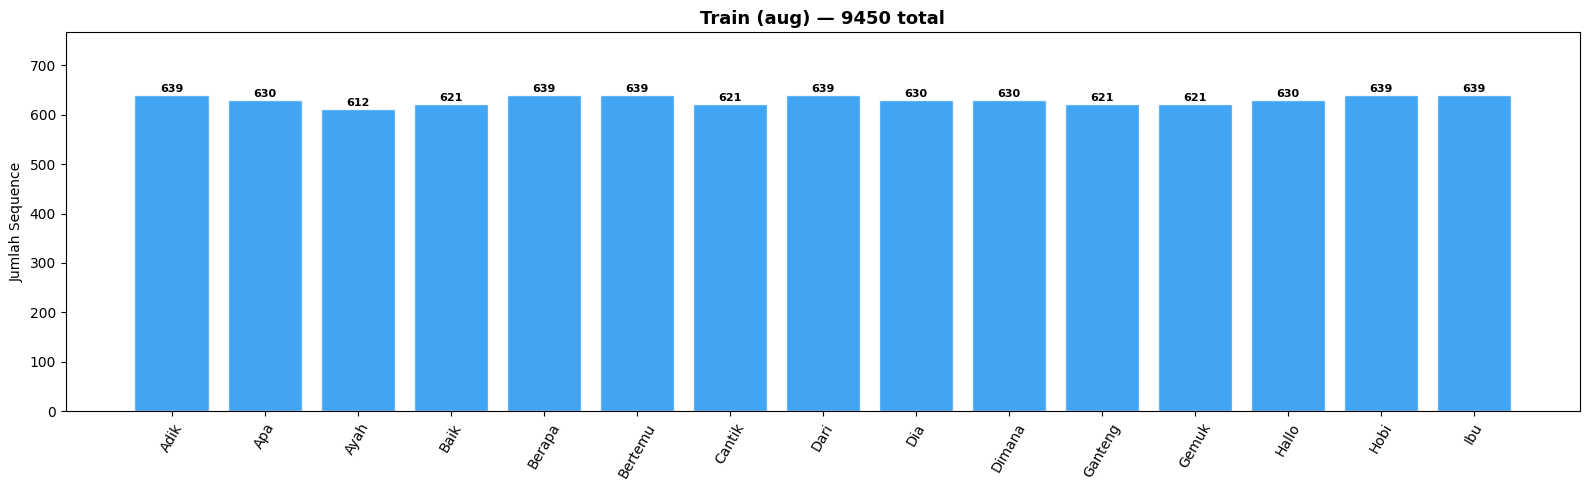

In [8]:
fig, ax = plt.subplots(figsize=(16, 5))
counts = np.sum(y_train, axis=0).astype(int)
bars = ax.bar(actions, counts, color='#2196F3', alpha=0.85, edgecolor='white')
ax.set_title(f'Train (aug) — {y_train.shape[0]} total', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Sequence')
ax.set_ylim(0, max(counts) * 1.2)
ax.tick_params(axis='x', rotation=60)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.01,
            str(c), ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_train.png', dpi=150, bbox_inches='tight')
plt.show()

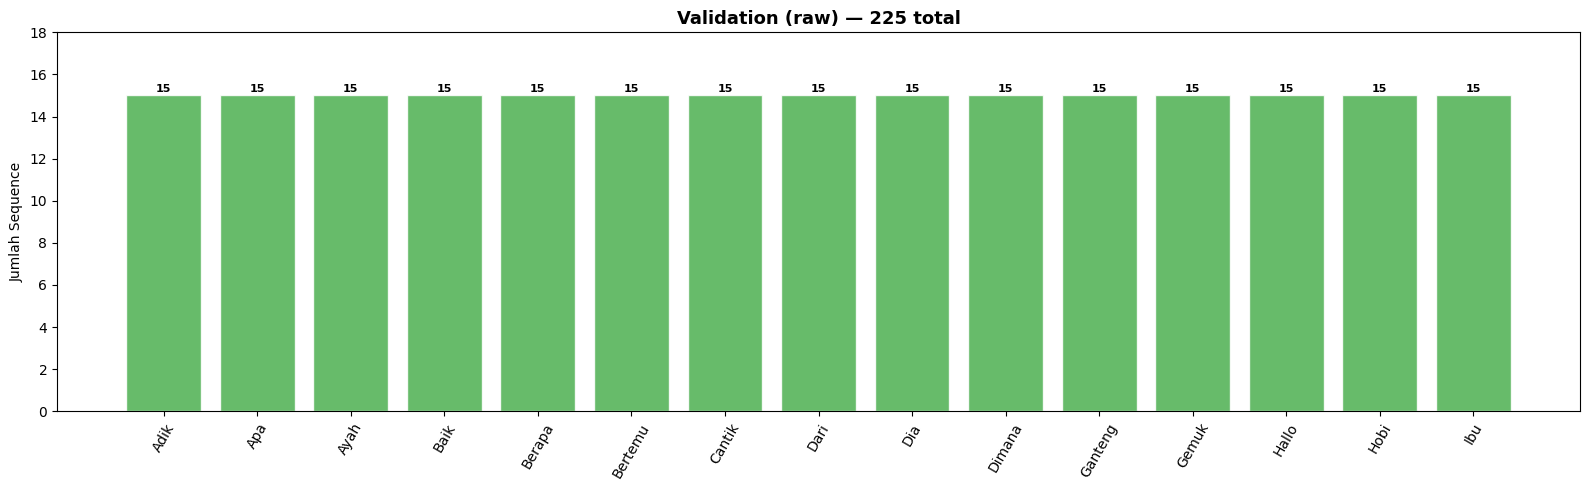

In [9]:
fig, ax = plt.subplots(figsize=(16, 5))
counts = np.sum(y_val, axis=0).astype(int)
bars = ax.bar(actions, counts, color='#4CAF50', alpha=0.85, edgecolor='white')
ax.set_title(f'Validation (raw) — {y_val.shape[0]} total', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Sequence')
ax.set_ylim(0, max(counts) * 1.2)
ax.tick_params(axis='x', rotation=60)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.01,
            str(c), ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_val.png', dpi=150, bbox_inches='tight')
plt.show()

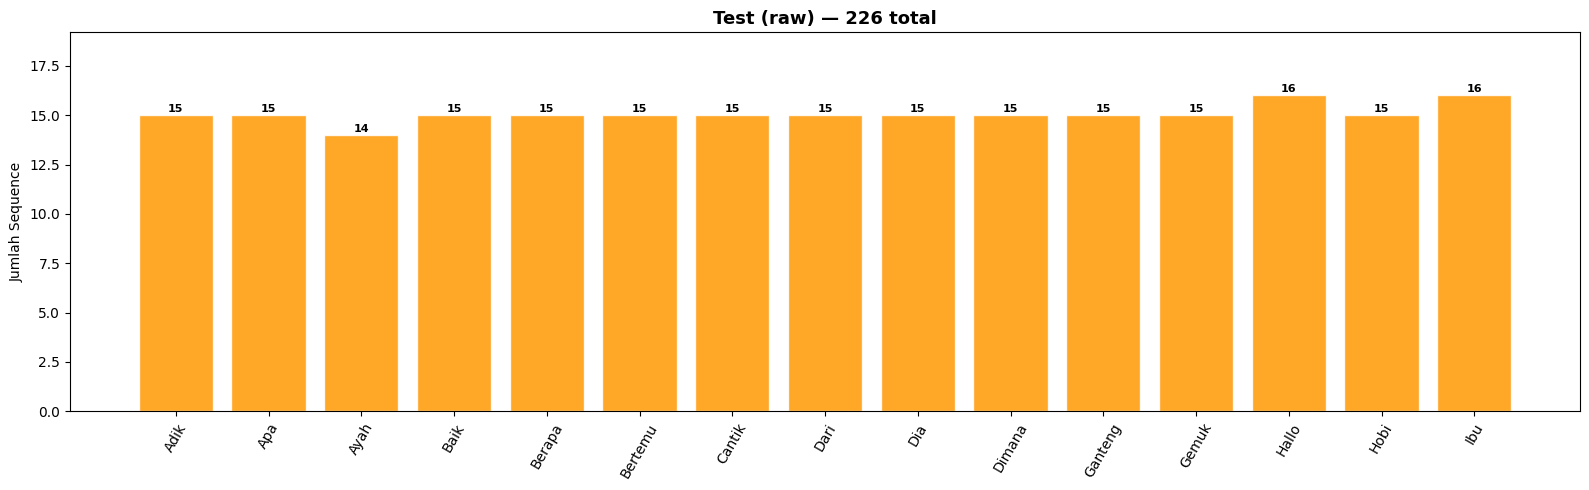

In [10]:
fig, ax = plt.subplots(figsize=(16, 5))
counts = np.sum(y_test, axis=0).astype(int)
bars = ax.bar(actions, counts, color='#FF9800', alpha=0.85, edgecolor='white')
ax.set_title(f'Test (raw) — {y_test.shape[0]} total', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Sequence')
ax.set_ylim(0, max(counts) * 1.2)
ax.tick_params(axis='x', rotation=60)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.01,
            str(c), ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_test.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
class AttentionLayer(Layer):
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(shape=(input_shape[1], 1),
                                 initializer='zeros', trainable=True)
        super().build(input_shape)

    def call(self, x):
        e = tf.nn.tanh(tf.matmul(x, self.W) + self.b)
        a = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(x * a, axis=1)

    def get_config(self):
        return super().get_config()

@tf.keras.utils.register_keras_serializable(package='custom')
class FocalLossWithSmoothing(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 name='focal_loss_with_smoothing', **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma
        self.alpha = alpha if alpha is not None else [1.0] * 25
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        n_classes = tf.shape(y_pred)[-1]
        # Label smoothing
        y_true_smooth = y_true * (1.0 - self.label_smoothing) + \
                        self.label_smoothing / tf.cast(n_classes, tf.float32)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true_smooth * tf.math.log(y_pred)

        alpha_tensor = tf.constant(self.alpha, dtype=tf.float32)
        pt = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        alpha_w = tf.reduce_sum(y_true * alpha_tensor, axis=-1, keepdims=True)
        focal_w = alpha_w * tf.pow(1.0 - pt, self.gamma)
        return tf.reduce_mean(focal_w * ce)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            'gamma': self.gamma,
            'alpha': self.alpha,
            'label_smoothing': self.label_smoothing,
        })
        return cfg


def build_model(seq_len, n_features, n_classes):
    inputs = Input(shape=(seq_len, n_features))

    # Input noise ringan → regularisasi tambahan
    x = GaussianNoise(0.005)(inputs)

    # BiLSTM
    x = Bidirectional(LSTM(96, return_sequences=True,
                           kernel_regularizer=l2(0.001),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Bidirectional(LSTM(64, return_sequences=True,
                           kernel_regularizer=l2(0.001),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = AttentionLayer()(x)

    # Dense
    x = Dense(192, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Dense(96, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = Dropout(0.3)(x)

    x = Dense(48, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = Dropout(0.2)(x)

    outputs = Dense(n_classes, activation='softmax')(x)
    return Model(inputs, outputs, name='BiLSTM_Attention_SIBI_15class_v2')

FOCAL_ALPHA = [1.0] * len(actions)  # uniform, confusable-class weighting tidak dipakai untuk saat ini

model = build_model(sequence_length, FITUR_PER_FRAME, len(actions))
model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss=FocalLossWithSmoothing(gamma=2.0, alpha=FOCAL_ALPHA, label_smoothing=0.05),
    metrics=['accuracy']
)
model.summary()

with open(f'{PATH_CONFIGURATION_GENERAL}/model_summary.txt', 'w', encoding='utf-8') as f:
    model.summary(print_fn=lambda x: f.write(x + '\n'))
print("✅ Model summary tersimpan : model_summary.txt")

I0000 00:00:1793093627.808939  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793093627.809043  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793093627.809064  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793093627.953586  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793093627.953690  148276 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-27

Model: "BiLSTM_Attention_SIBI_15class_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 30, 192)        │       272,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 192)        │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 192)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 30, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ (None, 128)            │           158 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 192)            │        24,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 192)            │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 96)             │        18,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 48)             │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │           735 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 455,117 (1.74 MB)

 Trainable params: 454,093 (1.73 MB)

 Non-trainable params: 1,024 (4.00 KB)

✅ Model summary tersimpan : model_summary.txt


In [12]:
import tensorflow as tf

checkpoint = ModelCheckpoint(
    TEMP_CHECKPOINT,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=60,
    min_delta=1e-4,
    restore_best_weights=True,
    mode='min',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=15,
    min_lr=1e-6,
    mode='min',
    verbose=1
)


class PerClassAccuracyCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, y_val, actions, every_n=10):
        self.X_val   = X_val
        self.y_val   = y_val
        self.actions = actions
        self.every_n = every_n
        self.best_per_class = {a: 0.0 for a in actions}

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n != 0:
            return
        y_pred = np.argmax(self.model.predict(self.X_val, verbose=0), axis=1)
        y_true = np.argmax(self.y_val, axis=1)
        print(f'\n  [Epoch {epoch+1}] Per-class val accuracy:')
        for i, action in enumerate(self.actions):
            mask = (y_true == i)
            if mask.sum() == 0:
                continue
            acc_i = (y_pred[mask] == i).mean()
            if acc_i > self.best_per_class[action]:
                self.best_per_class[action] = acc_i
            flag = ' ⚠️ ' if acc_i < 0.85 else ''
            print(f'    {action:12s}: {acc_i*100:5.1f}% (best {self.best_per_class[action]*100:5.1f}%){flag}')



per_class_cb = PerClassAccuracyCallback(X_val, y_val, actions, every_n=10)

print('Memulai training...\n')
print('Catatan: training TIDAK pakai class_weight lagi → cegah double weighting')
print('         dengan focal alpha. Loss yang dipakai sudah handle imbalance.\n')

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOCHS,
    batch_size=64,
    callbacks=[early_stop, checkpoint, reduce_lr, per_class_cb],
    verbose=1,
    shuffle=True,
)

best_model = tf.keras.models.load_model(
    TEMP_CHECKPOINT,
    custom_objects={'AttentionLayer': AttentionLayer,
                    'FocalLossWithSmoothing': FocalLossWithSmoothing}
)

best_model.save(MODEL_OUTPUT)
best_model.save(MODEL_OUTPUT_H5)

if os.path.exists(TEMP_CHECKPOINT):
    os.remove(TEMP_CHECKPOINT)

print(f'\n✅ Model terbaik disimpan : {MODEL_OUTPUT}')
print(f'✅ Model tersimpan (.h5)    : {MODEL_OUTPUT_H5}')
print(f'   Total epoch berjalan   : {len(history.history["loss"])}')
print(f'   Val loss terbaik       : {min(history.history["val_loss"]):.4f}')
print(f'   Val accuracy terbaik   : {max(history.history["val_accuracy"])*100:.2f}%')
print(f'   Epoch terbaik (val_loss) : {np.argmin(history.history["val_loss"]) + 1}')

Memulai training...

Catatan: training TIDAK pakai class_weight lagi → cegah double weighting
         dengan focal alpha. Loss yang dipakai sudah handle imbalance.

Epoch 1/500


2026-10-27 16:33:52.032488: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907


148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2190 - loss: 1.3474
Epoch 1: val_loss improved from None to 0.86061, saving model to Epoch500_20261027_162855/temp_checkpoint.keras
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - accuracy: 0.3418 - loss: 1.1361 - val_accuracy: 0.3244 - val_loss: 0.8606 - learning_rate: 5.0000e-04
Epoch 2/500
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6130 - loss: 0.6787
Epoch 2: val_loss improved from 0.86061 to 0.49985, saving model to Epoch500_20261027_162855/temp_checkpoint.keras
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.6744 - loss: 0.5899 - val_accuracy: 0.5511 - val_loss: 0.4998 - learning_rate: 5.0000e-04
Epoch 3/500
147/148 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8069 - loss: 0.3896
Epoch 3: val_loss improved from 0.49985 to 0.31523, saving model to Epoch500_20261027_162855/temp_checkpoint.keras
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8362 - loss: 0.3462 - val_accuracy: 0.5111 - val_loss: 0.3


✅ Model terbaik disimpan : Epoch500_20261027_162855/model15class.keras
✅ Model tersimpan (.h5)    : Epoch500_20261027_162855/model15class.h5
   Total epoch berjalan   : 230
   Val loss terbaik       : 0.0016
   Val accuracy terbaik   : 100.00%
   Epoch terbaik (val_loss) : 219


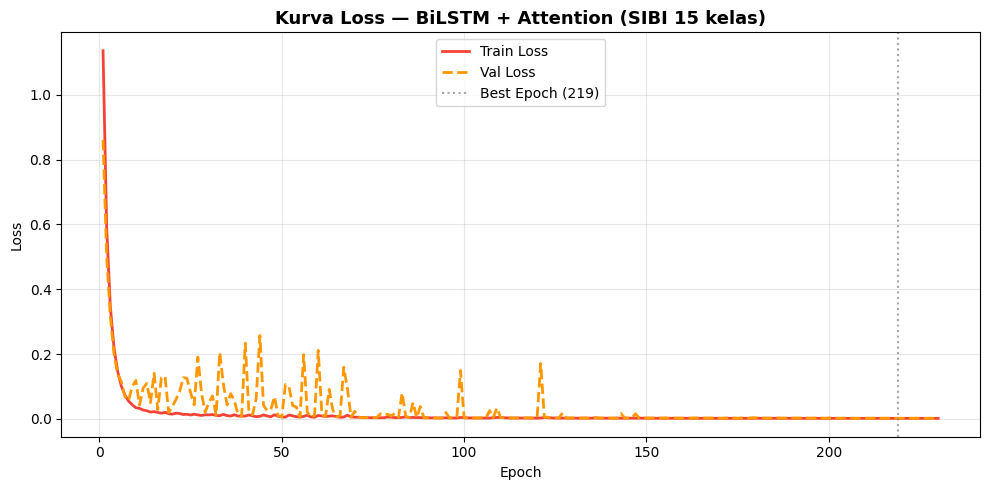

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
epochs_range = range(1, len(history.history['loss']) + 1)

ax.plot(epochs_range, history.history['loss'],
        color='#F44336', linewidth=2, label='Train Loss')
ax.plot(epochs_range, history.history['val_loss'],
        color='#FF9800', linewidth=2, linestyle='--', label='Val Loss')
best_ep = np.argmin(history.history['val_loss']) + 1
ax.axvline(x=best_ep, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep})')
ax.set_title('Kurva Loss — BiLSTM + Attention (SIBI 15 kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_loss.png', dpi=150, bbox_inches='tight')
plt.show()

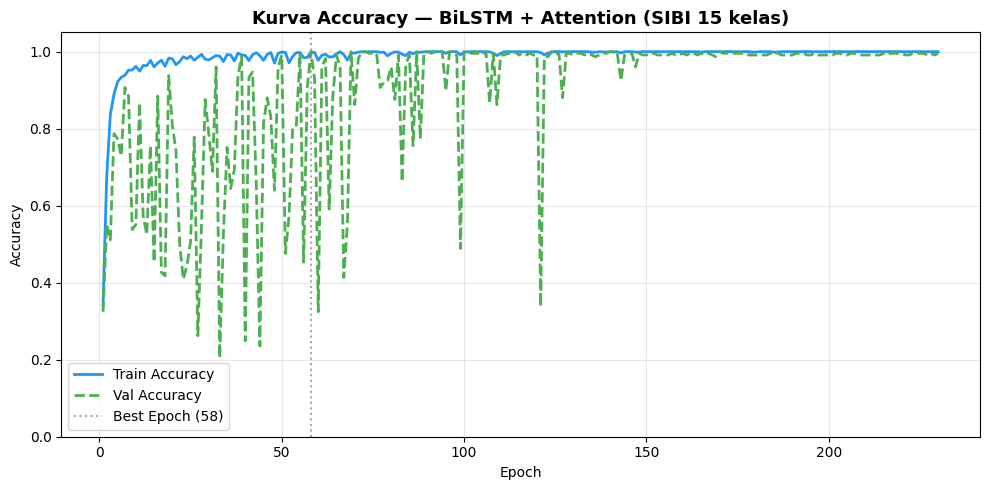

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(epochs_range, history.history['accuracy'],
        color='#2196F3', linewidth=2, label='Train Accuracy')
ax.plot(epochs_range, history.history['val_accuracy'],
        color='#4CAF50', linewidth=2, linestyle='--', label='Val Accuracy')
best_ep_acc = np.argmax(history.history['val_accuracy']) + 1
ax.axvline(x=best_ep_acc, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep_acc})')
ax.set_title('Kurva Accuracy — BiLSTM + Attention (SIBI 15 kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

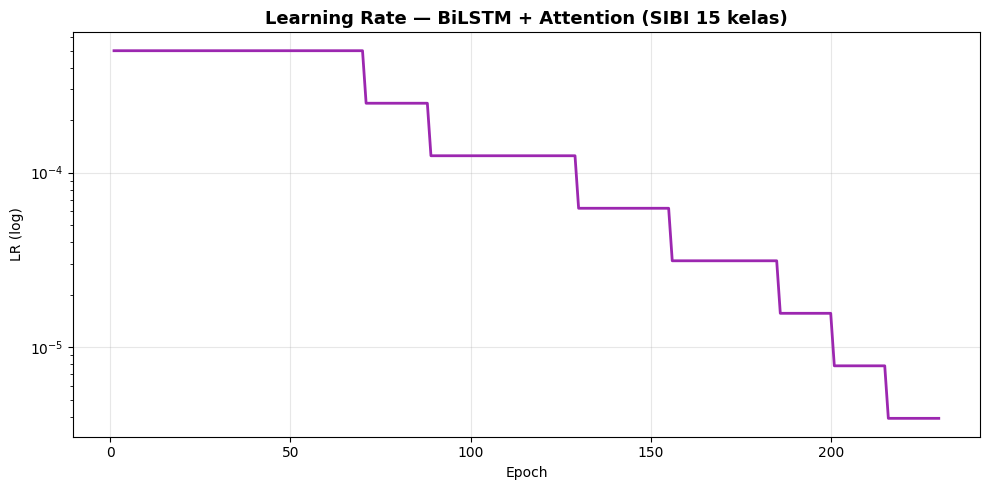

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

if 'learning_rate' in history.history:
    ax.plot(epochs_range, history.history['learning_rate'],
            color='#9C27B0', linewidth=2)
    ax.set_yscale('log')
    ax.set_title('Learning Rate — BiLSTM + Attention (SIBI 15 kelas)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR (log)')
    ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'LR history\ntidak tersedia',
            ha='center', va='center', transform=ax.transAxes)
    ax.set_title('Learning Rate', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_learning_rate.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
loss, acc = best_model.evaluate(X_test, y_test, verbose=0)
print('=' * 50)
print(f'  TEST ACCURACY : {acc * 100:.2f}%')
print(f'  TEST LOSS     : {loss:.4f}')
print('=' * 50)

y_pred_prob = best_model.predict(X_test, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = np.argmax(y_test,      axis=1)

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=actions))

report_str = classification_report(y_true, y_pred, target_names=actions)
with open(f'{PATH_CONFIGURATION_GENERAL}/classification_report.txt', 'w') as f:
    f.write(f"Test Accuracy : {acc*100:.2f}%\n")
    f.write(f"Test Loss     : {loss:.4f}\n\n")
    f.write(report_str)
print("✅ Classification report tersimpan")

  TEST ACCURACY : 100.00%
  TEST LOSS     : 0.0014

Classification Report:
              precision    recall  f1-score   support

        Adik       1.00      1.00      1.00        15
         Apa       1.00      1.00      1.00        15
        Ayah       1.00      1.00      1.00        14
        Baik       1.00      1.00      1.00        15
      Berapa       1.00      1.00      1.00        15
     Bertemu       1.00      1.00      1.00        15
      Cantik       1.00      1.00      1.00        15
        Dari       1.00      1.00      1.00        15
         Dia       1.00      1.00      1.00        15
      Dimana       1.00      1.00      1.00        15
     Ganteng       1.00      1.00      1.00        15
       Gemuk       1.00      1.00      1.00        15
       Hallo       1.00      1.00      1.00        16
        Hobi       1.00      1.00      1.00        15
         Ibu       1.00      1.00      1.00        16

    accuracy                           1.00       226
   ma

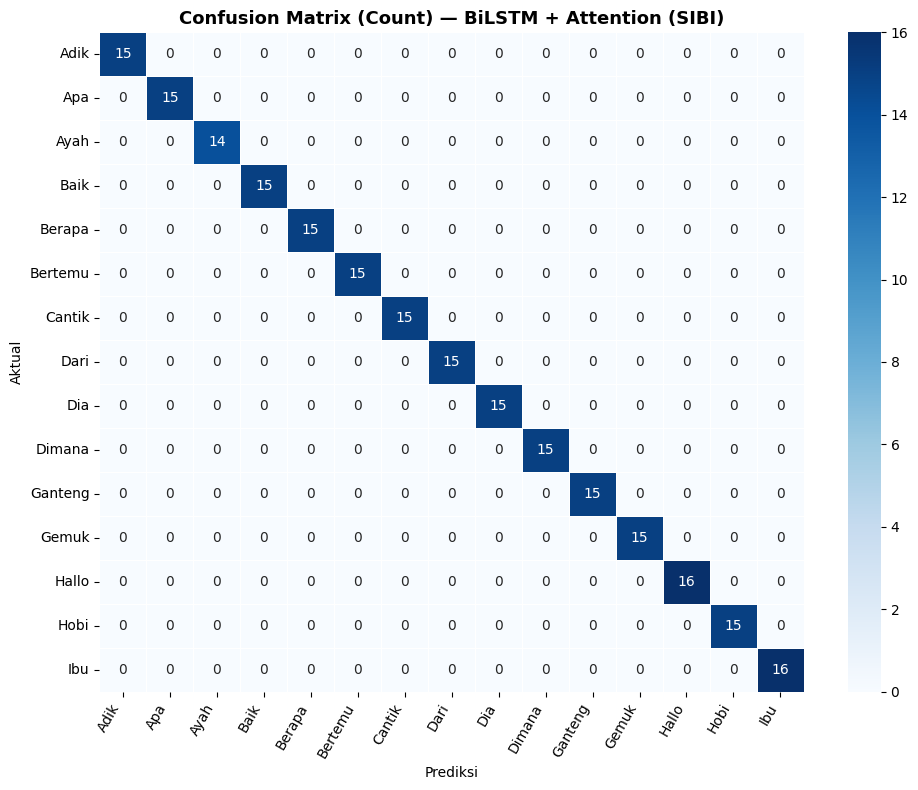

In [17]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.45), max(8, len(actions) * 0.4)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.5, linecolor='white')
ax.set_title('Confusion Matrix (Count) — BiLSTM + Attention (SIBI)', fontweight='bold', fontsize=13)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.xticks(rotation=60, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_count.png', dpi=150, bbox_inches='tight')
plt.show()

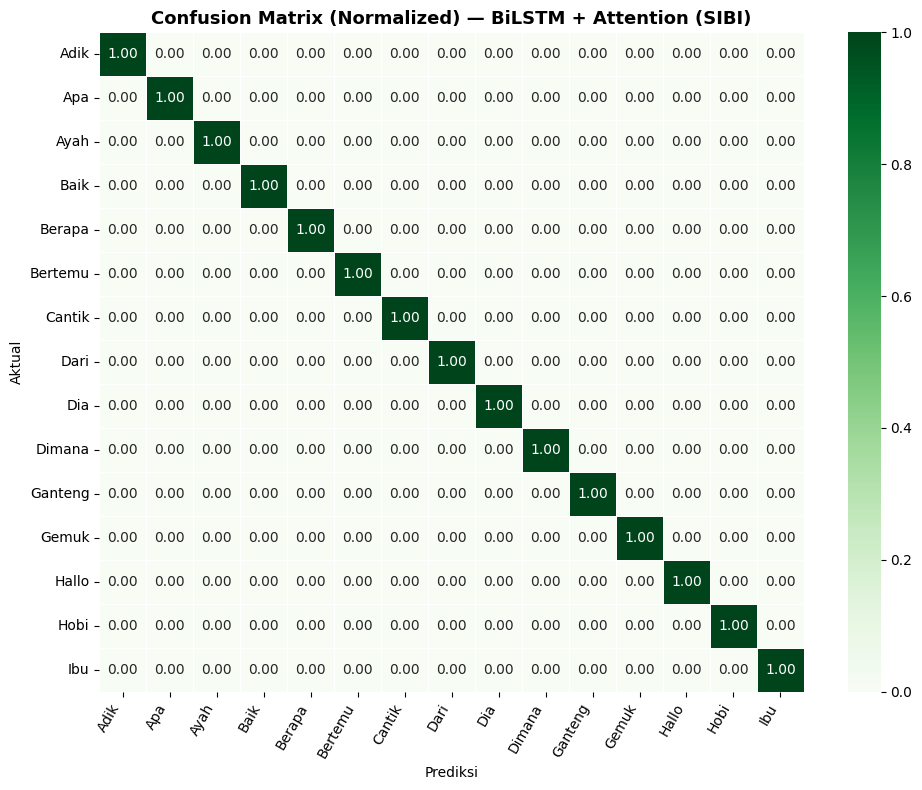

In [18]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.45), max(8, len(actions) * 0.4)))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.5, linecolor='white', vmin=0, vmax=1)
ax.set_title('Confusion Matrix (Normalized) — BiLSTM + Attention (SIBI)', fontweight='bold', fontsize=13)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.xticks(rotation=60, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_normalized.png', dpi=150, bbox_inches='tight')
plt.show()

In [19]:
print('\n⚠️  Confusable Pairs:')
for i in range(len(actions)):
    for j in range(len(actions)):
        if i != j and cm[i][j] > 0:
            print(f'  {actions[i]} → diprediksi {actions[j]}: {cm[i][j]} kali')


⚠️  Confusable Pairs:


In [20]:
report    = classification_report(y_true, y_pred,
                                   target_names=actions, output_dict=True)
df_report = pd.DataFrame(report).transpose().loc[actions]

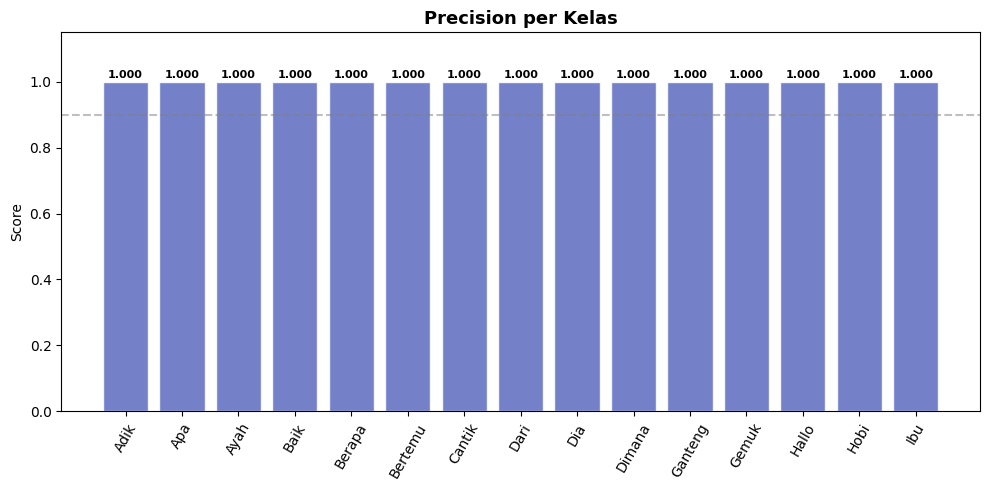

In [21]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.35), 5))
vals = df_report['precision'].values
bars = ax.bar(actions, vals, color='#5C6BC0', alpha=0.85, edgecolor='white')
ax.set_title('Precision per Kelas', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=60)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_precision.png', dpi=150, bbox_inches='tight')
plt.show()

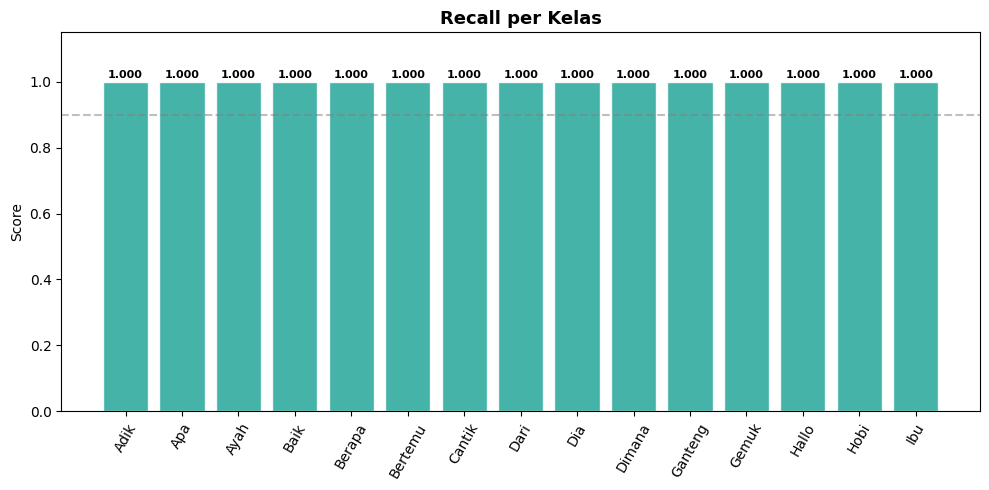

In [22]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.35), 5))
vals = df_report['recall'].values
bars = ax.bar(actions, vals, color='#26A69A', alpha=0.85, edgecolor='white')
ax.set_title('Recall per Kelas', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=60)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_recall.png', dpi=150, bbox_inches='tight')
plt.show()

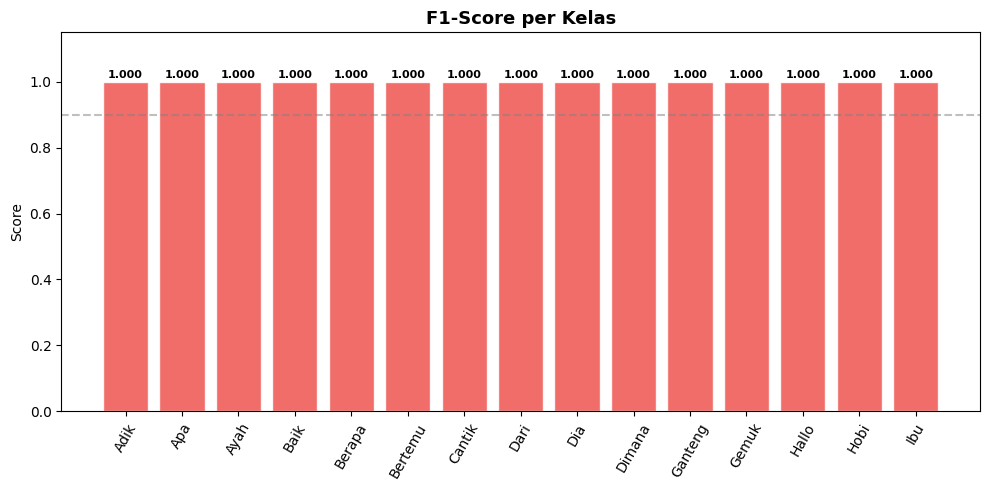

In [23]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.35), 5))
vals = df_report['f1-score'].values
bars = ax.bar(actions, vals, color='#EF5350', alpha=0.85, edgecolor='white')
ax.set_title('F1-Score per Kelas', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=60)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_f1score.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
print(df_report[['precision','recall','f1-score','support']].to_string())

         precision  recall  f1-score  support
Adik           1.0     1.0       1.0     15.0
Apa            1.0     1.0       1.0     15.0
Ayah           1.0     1.0       1.0     14.0
Baik           1.0     1.0       1.0     15.0
Berapa         1.0     1.0       1.0     15.0
Bertemu        1.0     1.0       1.0     15.0
Cantik         1.0     1.0       1.0     15.0
Dari           1.0     1.0       1.0     15.0
Dia            1.0     1.0       1.0     15.0
Dimana         1.0     1.0       1.0     15.0
Ganteng        1.0     1.0       1.0     15.0
Gemuk          1.0     1.0       1.0     15.0
Hallo          1.0     1.0       1.0     16.0
Hobi           1.0     1.0       1.0     15.0
Ibu            1.0     1.0       1.0     16.0


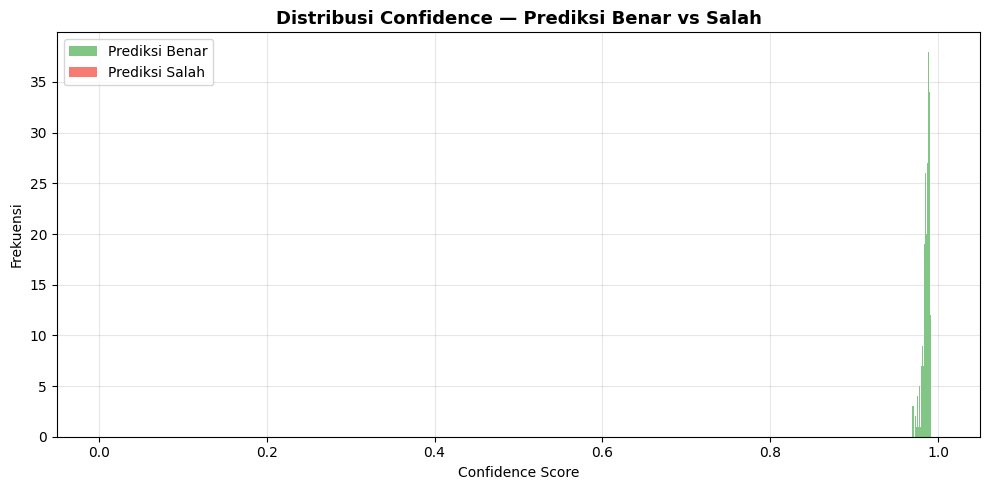

Confidence rata-rata benar : 0.9857
Confidence rata-rata salah : nan


In [25]:
max_conf   = np.max(y_pred_prob, axis=1)
is_correct = (y_pred == y_true)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_conf[is_correct],  bins=20, alpha=0.7,
        color='#4CAF50', label='Prediksi Benar')
ax.hist(max_conf[~is_correct], bins=20, alpha=0.7,
        color='#F44336', label='Prediksi Salah')
ax.set_title('Distribusi Confidence — Prediksi Benar vs Salah', fontweight='bold', fontsize=13)
ax.set_xlabel('Confidence Score'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Confidence rata-rata benar : {max_conf[is_correct].mean():.4f}')
print(f'Confidence rata-rata salah : {max_conf[~is_correct].mean():.4f}')

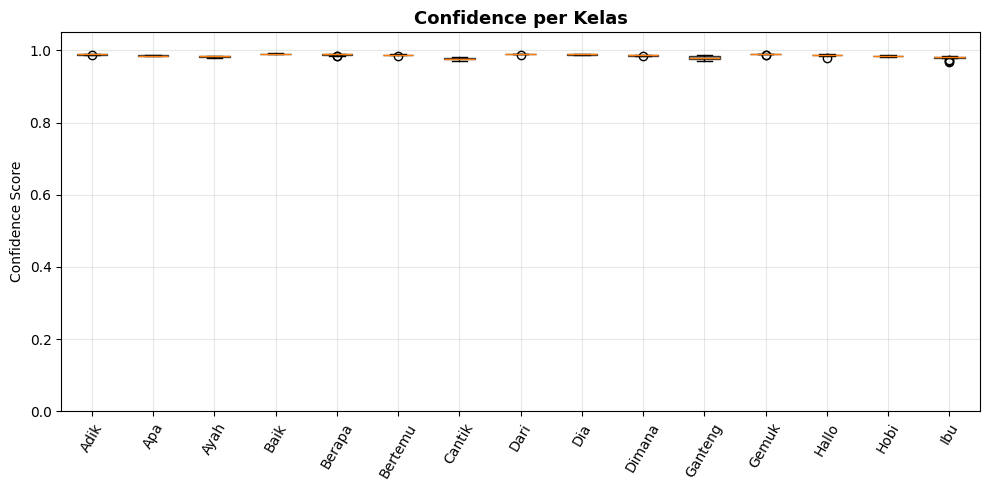

In [26]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.4), 5))
bp = ax.boxplot(
    [max_conf[y_true == i] for i in range(len(actions))],
    labels=actions, patch_artist=True
)

# generate warna sebanyak jumlah kelas (bukan list tetap 11 warna)
colors_cycle = plt.cm.tab20(np.linspace(0, 1, len(actions)))
for patch, c in zip(bp['boxes'], colors_cycle):
    patch.set_facecolor(c); patch.set_alpha(0.75)

ax.set_title('Confidence per Kelas', fontweight='bold', fontsize=13)
ax.set_ylabel('Confidence Score'); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
report_full = classification_report(
    y_true, y_pred, target_names=actions, output_dict=True
)

print('=' * 60)
print('        RINGKASAN HASIL TRAINING — SIBI 15 KELAS (v2)')
print('=' * 60)
print(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing')
print(f'  Kelas         : {", ".join(actions)}')
print(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi')
print(f'  Fitur/frame   : {FITUR_PER_FRAME}')
print(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik')
print('-' * 60)
print(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}')
print('-' * 60)
print(f'  Test Accuracy : {acc * 100:.2f}%')
print(f'  Test Loss     : {loss:.4f}')
print(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}')
print(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}')
print('-' * 60)
print('  Per-Class:')
for action in actions:
    r = report_full[action]
    print(f'  {action:12s}  P={r["precision"]:.3f}  '
          f'R={r["recall"]:.3f}  F1={r["f1-score"]:.3f}')
print('=' * 60)
print(f'\n✅ Output model  : {MODEL_OUTPUT}')

with open(f'{PATH_CONFIGURATION_GENERAL}/ringkasan_training.txt', 'w', encoding='utf-8') as f:
    f.write('=' * 60 + '\n')
    f.write('        RINGKASAN HASIL TRAINING — SIBI 15 KELAS (v2)\n')
    f.write('=' * 60 + '\n')
    f.write(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing\n')
    f.write(f'  Kelas         : {", ".join(actions)}\n')
    f.write(f'  Jumlah Kelas  : {len(actions)}\n')
    f.write(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi\n')
    f.write(f'  Fitur/frame   : {FITUR_PER_FRAME}\n')
    f.write(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Test Accuracy : {acc * 100:.2f}%\n')
    f.write(f'  Test Loss     : {loss:.4f}\n')
    f.write(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}\n')
    f.write(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}\n')
    f.write(f'  Macro P       : {report_full["macro avg"]["precision"]:.4f}\n')
    f.write(f'  Macro R       : {report_full["macro avg"]["recall"]:.4f}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Epoch terbaik (val_accuracy) : {np.argmax(history.history["val_accuracy"]) + 1}\n')
    f.write(f'  Epoch terbaik (val_loss)     : {np.argmin(history.history["val_loss"]) + 1}\n')
    f.write(f'  Total epoch berjalan         : {len(history.history["loss"])}\n')
    f.write(f'  Val Accuracy terbaik         : {max(history.history["val_accuracy"]) * 100:.2f}%\n')
    f.write(f'  Val Loss terbaik             : {min(history.history["val_loss"]):.4f}\n')
    f.write('-' * 60 + '\n')
    f.write('  Per-Class Metrics:\n')
    f.write(f'  {"Kelas":<14} {"Precision":>10} {"Recall":>10} {"F1-Score":>10} {"Support":>10}\n')
    f.write('  ' + '-' * 50 + '\n')
    for action in actions:
        r = report_full[action]
        f.write(f'  {action:<14} {r["precision"]:>10.4f} {r["recall"]:>10.4f} '
                f'{r["f1-score"]:>10.4f} {int(r["support"]):>10}\n')
    f.write('-' * 60 + '\n')
    f.write('=' * 60 + '\n')

print('✅ Ringkasan tersimpan : ringkasan_training.txt')

        RINGKASAN HASIL TRAINING — SIBI 15 KELAS (v2)
  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing
  Kelas         : Adik, Apa, Ayah, Baik, Berapa, Bertemu, Cantik, Dari, Dia, Dimana, Ganteng, Gemuk, Hallo, Hobi, Ibu
  Total data    : 1501 (asli) → train diaugmentasi
  Fitur/frame   : 258
  Sequence len  : 30 frame @ 30fps = 1.0 detik
------------------------------------------------------------
  Train (aug) / Val / Test : 9450 / 225 / 226
------------------------------------------------------------
  Test Accuracy : 100.00%
  Test Loss     : 0.0014
  Macro F1      : 1.0000
  Weighted F1   : 1.0000
------------------------------------------------------------
  Per-Class:
  Adik          P=1.000  R=1.000  F1=1.000
  Apa           P=1.000  R=1.000  F1=1.000
  Ayah          P=1.000  R=1.000  F1=1.000
  Baik          P=1.000  R=1.000  F1=1.000
  Berapa        P=1.000  R=1.000  F1=1.000
  Bertemu       P=1.000  R=1.000  F1=1.000
  Cantik        P=1.000  R=1.000  F1=1.

In [28]:
# ==============================================================================
# SIMPAN DOKUMENTASI KELAS YANG DILATIH KE FILE .MD (MARKDOWN)
# ==============================================================================
import os
from datetime import datetime

MD_OUTPUT_PATH = f'{PATH_CONFIGURATION_GENERAL}/daftar_kelas.md'
waktu_training = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

# Hitung statistik data per kelas
train_raw_counts = dict(zip(*np.unique(y_train_raw, return_counts=True)))
val_raw_counts   = dict(zip(*np.unique(y_val_raw, return_counts=True)))
test_raw_counts  = dict(zip(*np.unique(y_test_raw, return_counts=True)))
train_aug_counts = dict(zip(*np.unique(y_train_int, return_counts=True)))

md_content = f"""# Dokumentasi Model SIBI Recognition — {len(actions)} Kelas

> Dokumen ini dibuat otomatis pada akhir proses training untuk mencatat seluruh kelas kata yang dilatih pada sesi ini.

---

### 📌 Ringkasan Informasi Sesi Training
* **Waktu Selesai Training** : `{waktu_training}`
* **Jumlah Kelas**          : **{len(actions)} kata**
* **Arsitektur Model**       : BiLSTM (96 $\\rightarrow$ 64) + Attention Layer + Focal Loss + Label Smoothing
* **Dimensi Input**          : `(None, {sequence_length}, {FITUR_PER_FRAME})` (30 frame @ 30fps $\\times$ 258 keypoints)
* **File Output Model**      : `{os.path.basename(MODEL_OUTPUT)}` / `{os.path.basename(MODEL_OUTPUT_H5)}`
* **Folder Output**          : `{PATH_CONFIGURATION_GENERAL}`

---

### 📊 Performa Evaluasi Model
* **Test Accuracy** : **{acc * 100:.2f}%**
* **Test Loss**     : **{loss:.4f}**
* **Macro F1-Score**: **{report_full["macro avg"]["f1-score"]:.4f}**
* **Weighted F1**   : **{report_full["weighted avg"]["f1-score"]:.4f}**
* **Data Train (Asli / Setelah Aug)** : `{len(X_train_raw)}` / `{len(X_train)}` sequence
* **Data Val (Murni)**                : `{len(X_val_raw)}` sequence
* **Data Test (Murni)**               : `{len(X_test_raw)}` sequence

---

### 📋 Daftar Lengkap Kelas Kata yang Dilatih ({len(actions)} Kelas)

| No | Label Kelas (Action) | Data Train (Asli) | Train (Augmentasi) | Val (Asli) | Test (Asli) | Precision | Recall | F1-Score | Support |
|:---:|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
"""

for idx, action in enumerate(actions, 1):
    action_idx = label_map[action]
    tr_raw  = train_raw_counts.get(action_idx, 0)
    tr_aug  = train_aug_counts.get(action_idx, 0)
    vl_raw  = val_raw_counts.get(action_idx, 0)
    ts_raw  = test_raw_counts.get(action_idx, 0)
    
    r = report_full.get(action, {})
    prec = r.get("precision", 0.0)
    rec  = r.get("recall", 0.0)
    f1   = r.get("f1-score", 0.0)
    sup  = int(r.get("support", ts_raw))
    
    md_content += f"| {idx} | **{action}** | {tr_raw} | {tr_aug} | {vl_raw} | {ts_raw} | {prec:.3f} | {rec:.3f} | {f1:.3f} | {sup} |\n"

md_content += """
---

### 💡 Catatan Pipeline Augmentasi:
Model ini dilatih dengan 8 augmentasi khusus *right-hand dominant* & multi-jarak:
1. `aug_zoom_half_body` (1.40x - 2.05x zoom setengah badan khas webcam)
2. `aug_centered_scale` (0.85x - 1.35x variasi jarak natural)
3. `aug_translation` (+-8% pergeseran posisi duduk)
4. `aug_time_warp` (0.80x - 1.20x variasi kecepatan isyarat)
5. `aug_hand_dropout` (1-3 frame toleransi kedipan tracking)
6. `aug_visibility_variation` (tahan variasi visibility browser)
7. `aug_slight_rotation` (+-6 derajat kemiringan sudut webcam)
8. `aug_gaussian_noise` (noise sensor halus)
"""

with open(MD_OUTPUT_PATH, 'w', encoding='utf-8') as f:
    f.write(md_content)

print(f'✅ Berhasil menyimpan dokumentasi kelas (.md) ke:')
print(f'   {MD_OUTPUT_PATH}')


✅ Berhasil menyimpan dokumentasi kelas (.md) ke:
   Epoch500_20261027_162855/daftar_kelas.md


In [29]:
# ==============================================================================
# EKSPOR OTOMATIS KE FORMAT TENSORFLOW.JS (UNTUK FRONTEND TFJS / NEXT.JS)
# ==============================================================================
import subprocess
import shutil

TFJS_OUTPUT_DIR = f'{PATH_CONFIGURATION_GENERAL}/tfjs_model15class'
os.makedirs(TFJS_OUTPUT_DIR, exist_ok=True)

print(f'=== Mengekspor model Keras ke format TensorFlow.js ===')
print(f'Model input : {MODEL_OUTPUT_H5}')
print(f'Output dir  : {TFJS_OUTPUT_DIR}')

# Cari executable tensorflowjs_converter
tfjs_conv = shutil.which('tensorflowjs_converter')
if not tfjs_conv:
    potential_paths = [
        os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'venv', 'Scripts', 'tensorflowjs_converter.exe')),
        os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'venv', 'bin', 'tensorflowjs_converter')),
        os.path.abspath('/mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/bin/tensorflowjs_converter'),
        os.path.abspath('/mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/tensorflowjs_converter.exe'),
        os.path.abspath('D:/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/tensorflowjs_converter.exe')
    ]
    for p in potential_paths:
        if os.path.exists(p):
            tfjs_conv = p
            break

if tfjs_conv:
    print(f'Menggunakan converter: {tfjs_conv}')
    cmd = [
        tfjs_conv,
        '--input_format=keras',
        MODEL_OUTPUT_H5,
        TFJS_OUTPUT_DIR
    ]
    res = subprocess.run(cmd, capture_output=True, text=True)
    if res.returncode == 0:
        print(f'✅ Konversi berhasil!')
        print(f'   File hasil: {os.listdir(TFJS_OUTPUT_DIR)}')
        
        # Salin juga file dokumentasi kelas (.md) ke dalam folder TFJS
        md_file = f'{PATH_CONFIGURATION_GENERAL}/daftar_kelas.md'
        if os.path.exists(md_file):
            shutil.copy2(md_file, os.path.join(TFJS_OUTPUT_DIR, 'daftar_kelas.md'))
            print('✅ File daftar_kelas.md ikut disertakan ke paket TFJS')
        
        # Salin otomatis ke Frontend/public/models/tfjs_model15class
        fe_candidates = [
            os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'Frontend', 'public', 'models', 'tfjs_model15class')),
            os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..', 'Frontend', 'public', 'models', 'tfjs_model15class')),
            'D:/Projects/SIBI Recognition Lecturers/Frontend/public/models/tfjs_model15class',
            '/mnt/d/Projects/SIBI Recognition Lecturers/Frontend/public/models/tfjs_model15class'
        ]
        copied = False
        for fe_dir in fe_candidates:
            parent_dir = os.path.dirname(fe_dir)
            if os.path.exists(parent_dir):
                os.makedirs(fe_dir, exist_ok=True)
                for f in os.listdir(TFJS_OUTPUT_DIR):
                    src_f = os.path.join(TFJS_OUTPUT_DIR, f)
                    dst_f = os.path.join(fe_dir, f)
                    if os.path.isfile(src_f):
                        shutil.copy2(src_f, dst_f)
                print(f'✅ Berhasil disalin otomatis ke Frontend: {fe_dir}')
                copied = True
                break
        if not copied:
            print(f'ℹ️  Silakan salin manual isi folder {TFJS_OUTPUT_DIR} ke Frontend/public/models/tfjs_model15class/')
    else:
        print(f'⚠️ Konversi gagal dengan pesan:\n{res.stderr}')
else:
    print('⚠️ CLI tensorflowjs_converter tidak ditemukan otomatis.')
    print(f'   Silakan jalankan di terminal:')
    print(f'   tensorflowjs_converter --input_format=keras "{MODEL_OUTPUT_H5}" "{TFJS_OUTPUT_DIR}"')


=== Mengekspor model Keras ke format TensorFlow.js ===
Model input : Epoch500_20261027_162855/model15class.h5
Output dir  : Epoch500_20261027_162855/tfjs_model15class
Menggunakan converter: /mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/tensorflowjs_converter.exe
✅ Konversi berhasil!
   File hasil: ['group1-shard1of1.bin', 'model.json']
✅ File daftar_kelas.md ikut disertakan ke paket TFJS
✅ Berhasil disalin otomatis ke Frontend: /mnt/d/Projects/SIBI Recognition Lecturers/Frontend/public/models/tfjs_model15class
